In [5]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os

In [6]:
sys.path.append(os.pardir)
import numpy as np
from ch03.sigmoid import sigmoid
from ch03.relu import relu
from ch03.tanh import tanh

In [ ]:
def forward_net(
    is_sd_const,
    sd,
    ac_func,
    input_data=np.random.randn(1000, 100),
    node_num=100,
    hidden_layer_size=5,
    activations={},
    hist_range=(0, 1),
):
    x = input_data
    # 標準正規分布に従う乱数なのでこの時点で分散は1
    print("入力の分散")
    print(np.var(x))
    for i in range(hidden_layer_size):  # 隠れ層数の分だけループ
        if i != 0:  # 初回以外は一個前の層の結果を入力とする
            x = activations[i - 1]
        if is_sd_const:
            w = np.random.randn(node_num, node_num) * sd
        else:
            w = np.random.randn(node_num, node_num) * np.sqrt(sd / node_num)

        a = np.dot(x, w)
        print("活性化前の分散")
        print(np.var(a))
        if not is_sd_const:
            print("活性化前の二乗平均")
            print(np.mean(a * a))

        # zが活性化関数を適用後の値
        z = ac_func(a)
        print("活性化後の平均と分散")
        print(np.mean(z))
        print(np.var(z))

        activations[i] = z

    # ヒストグラムを描画
    plt.figure(figsize=(20, 5))
    for i, a in activations.items():

        plt.subplot(1, len(activations), i + 1)
        plt.title(str(i + 1) + "-layer")
        if i != 0:
            plt.yticks([], [])
        # plt.xlim(0.1, 1)
        # plt.ylim(0, 7000)
        plt.hist(a.flatten(), 30, range=hist_range)
    plt.show()

前層のニューロン数かける重みの分散は100かける1で100

よってinputの分散1から約100倍になっている

綺麗に前層の活性値の100倍の分散になっている（tanhの活性値の平均が大体0より）

入力の分散
1.0078111689115792
活性化前の分散
101.7748431009556
活性化後の平均と分散
-0.001461371296774609
0.9205117515862854
活性化前の分散
93.44682535455189
活性化後の平均と分散
-0.009042238194430912
0.9176358265462582
活性化前の分散
88.8026864208138
活性化後の平均と分散
0.003469783699415389
0.9158332938434582
活性化前の分散
91.28513520334997
活性化後の平均と分散
5.983124987806718e-05
0.9166357375452242
活性化前の分散
92.14647892281745
活性化後の平均と分散
0.001453078926570887
0.9164824059629112


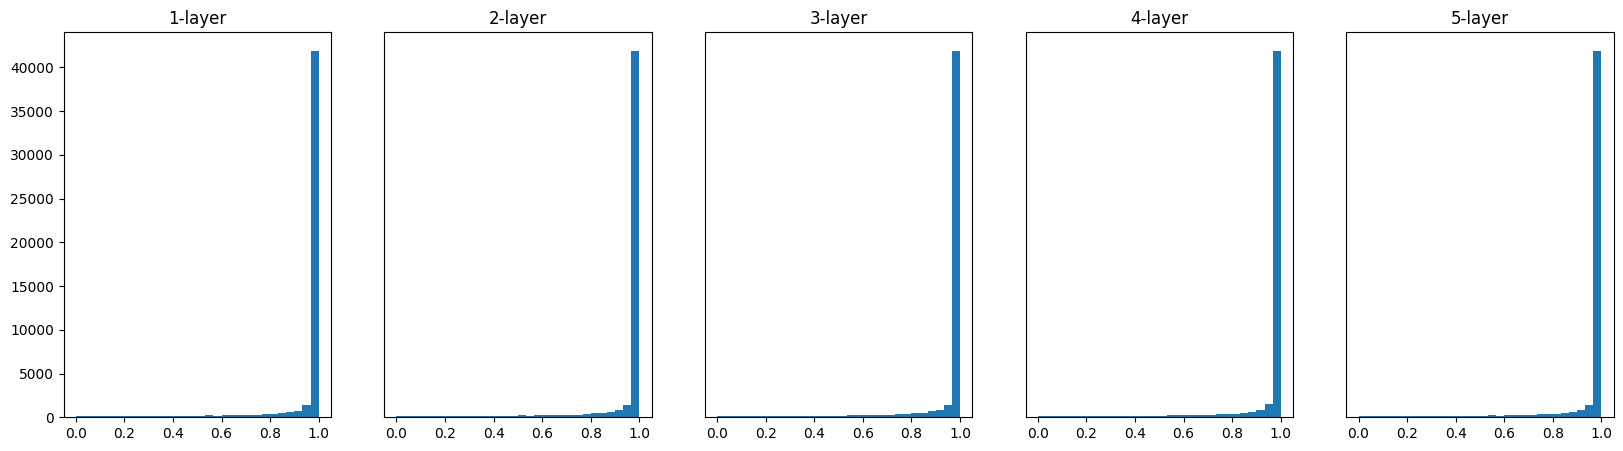

In [ ]:
forward_net(is_sd_const=True, sd=1, ac_func=tanh)

入力の分散
1.0078111689115792
活性化前の分散
102.44711169871384
活性化後の平均と分散
0.49935989789452667
0.21082627011599717
活性化前の分散
43.204939906978026
活性化後の平均と分散
0.49672688233944995
0.19288928399568794
活性化前の分散
43.24094021530801
活性化後の平均と分散
0.4764539627643426
0.19197958302152604
活性化前の分散
41.0506238051583
活性化後の平均と分散
0.4375455036121465
0.19307129247318552
活性化前の分散
42.1478495300825
活性化後の平均と分散
0.3797909458940229
0.18116843037265346


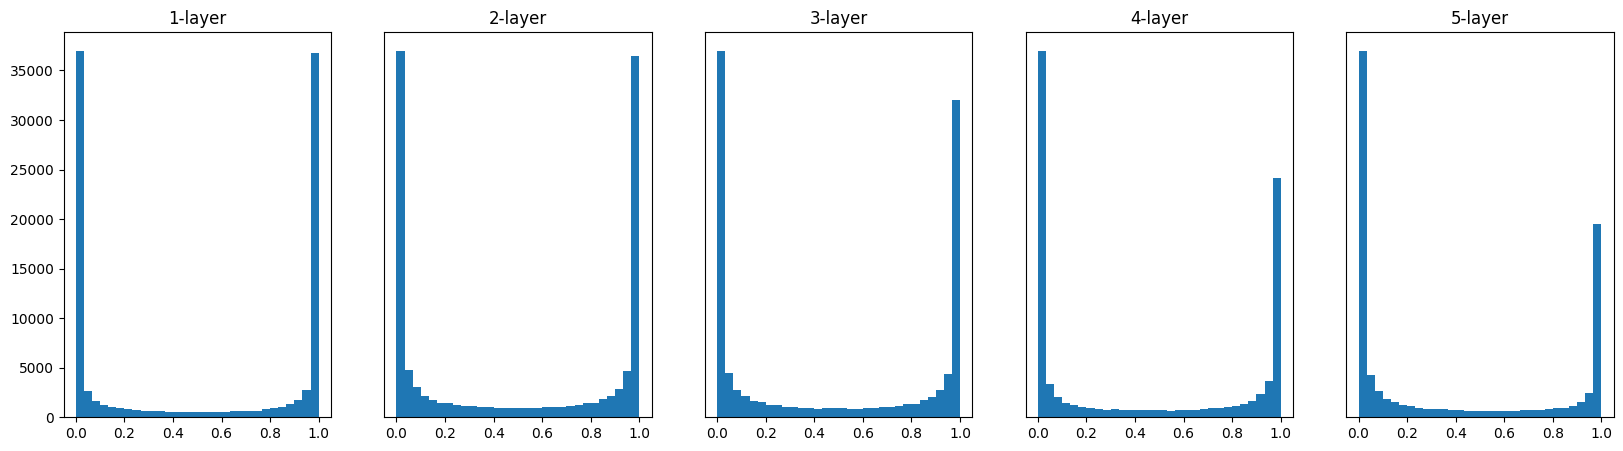

In [ ]:
forward_net(is_sd_const=True, sd=1, ac_func=sigmoid)

入力の分散
1.0078111689115792
活性化前の分散
0.9956408661753003
活性化後の平均と分散
0.5000279955626867
0.043005698201200086
活性化前の分散
0.17745414963836464
活性化後の平均と分散
0.4717190924061107
0.010097054734374108
活性化前の分散
0.2709387248882228
活性化後の平均と分散
0.5107093864584382
0.014497265695101137
活性化前の分散
0.21122313827751277
活性化後の平均と分散
0.4949702056514467
0.011538320484351678
活性化前の分散
0.23123542314500312
活性化後の平均と分散
0.5088662452881925
0.013175876106063524


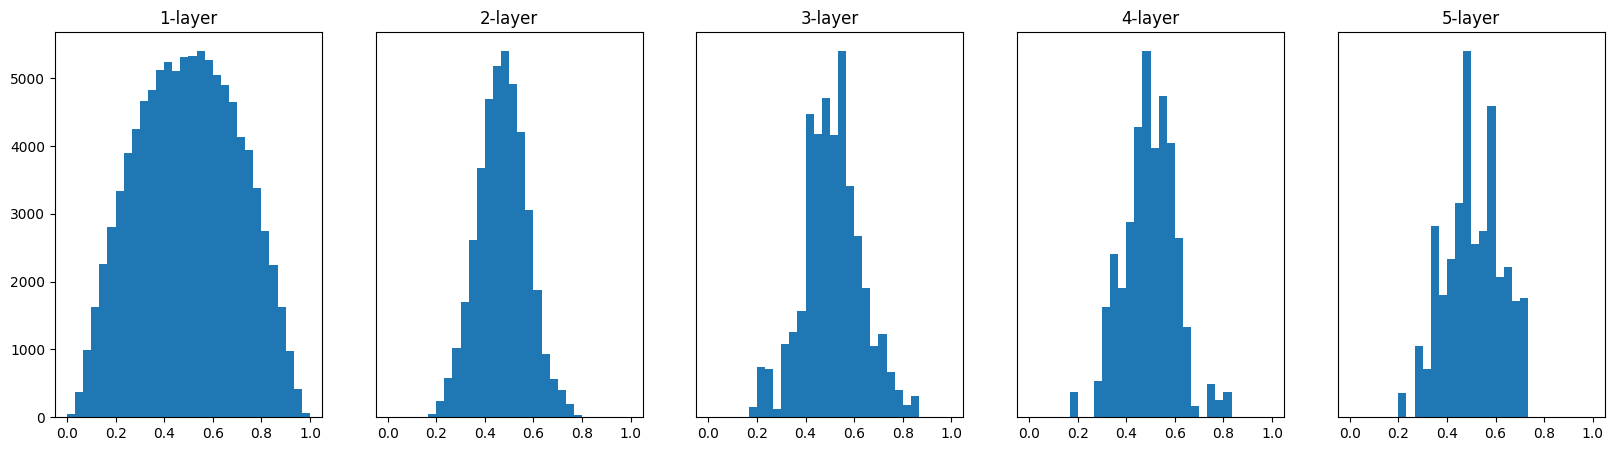

In [ ]:
forward_net(is_sd_const=False, sd=1, ac_func=sigmoid)

tanhの出力が平均0なので、綺麗に分散が保存される。

ただし、活性化関数により全体としては分散は小さくなっていく

入力の分散
1.000222312800325
活性化前の分散
1.0118926746671122
活性化前の二乗平均
1.011892784397476
活性化後の平均と分散
-0.00047541787177485256
0.39651007802522775
活性化前の分散
0.38765002615562916
活性化前の二乗平均
0.387651761182393
活性化後の平均と分散
0.0009459752257751406
0.23366146197994886
活性化前の分散
0.23617030898220553
活性化前の二乗平均
0.2361703763813302
活性化後の平均と分散
7.507369907864387e-05
0.1664328471384239
活性化前の分散
0.16466165381960562
活性化前の二乗平均
0.16466172249082167
活性化後の平均と分散
-0.00014323274409180488
0.12657993891580036
活性化前の分散
0.13321595958705332
活性化前の二乗平均
0.13321605376924125
活性化後の平均と分散
0.00020112000178981526
0.10692636535565848


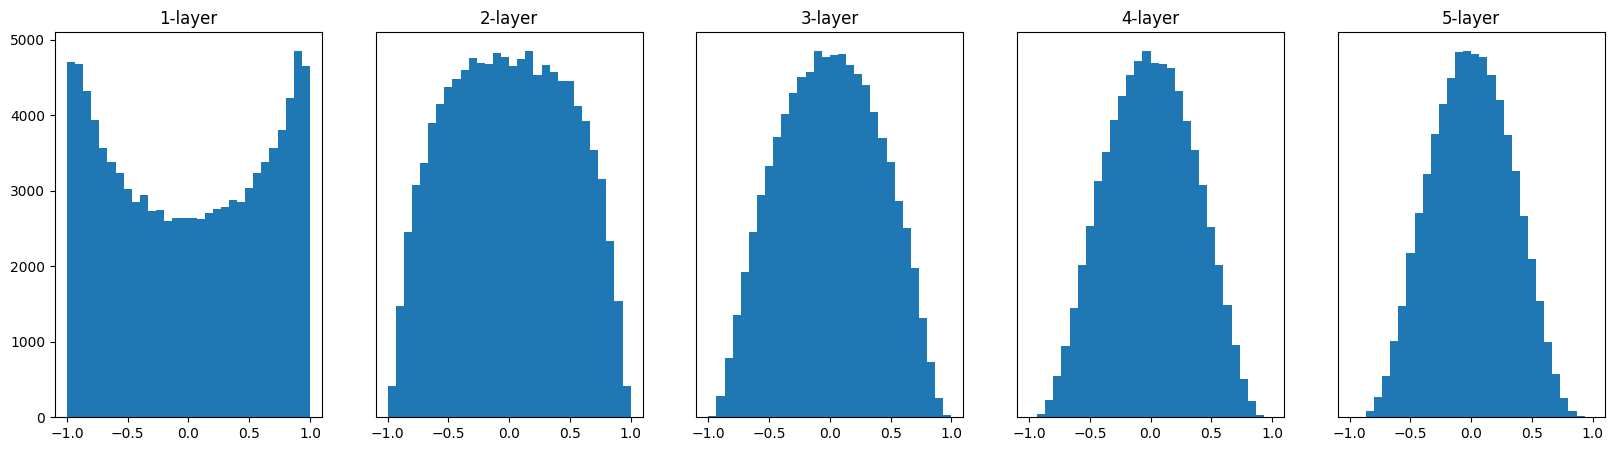

In [ ]:
forward_net(is_sd_const=False, sd=1, ac_func=tanh, hist_range=(-1, 1))

活性化前二乗平均=活性化前分散は大体2で維持されている

ただし層を重ねると小さくなる

入力の分散
0.9923944376122185
活性化前の分散
1.9650237725737891
活性化前の二乗平均
1.9650280146953536
活性化後の平均と分散
0.5566446705680663
0.6677049766840889
活性化前の分散
1.8925110177738669
活性化前の二乗平均
1.892871250813776
活性化後の平均と分散
0.5553172827363296
0.648395254454546
活性化前の分散
1.9870932671903383
活性化前の二乗平均
2.0152436855968605
活性化後の平均と分散
0.6469004604100477
0.7603703393382021
活性化前の分散
2.5643741284564747
活性化前の二乗平均
2.56910876353702
活性化後の平均と分散
0.6044444640425047
0.8498530355356466
活性化前の分散
2.2335694404651876
活性化前の二乗平均
2.241252983889046
活性化後の平均と分散
0.5518318308860396
0.6910161306214779


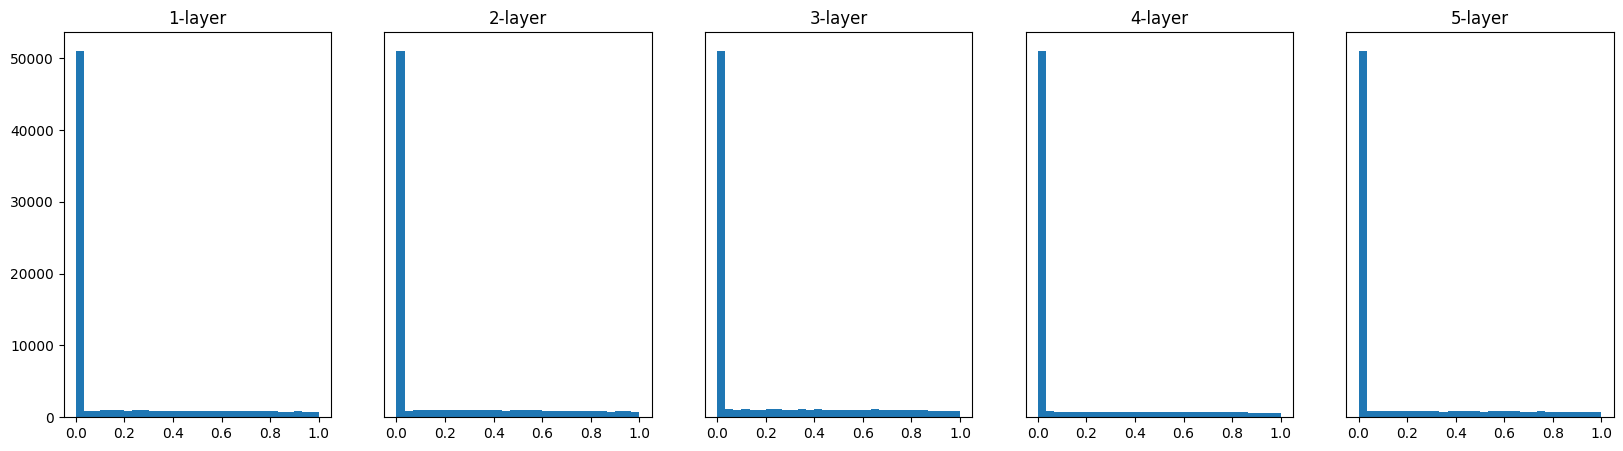

In [ ]:
forward_net(is_sd_const=False, sd=2, ac_func=relu)

活性化前の二乗平均が大体2分の1ずつくらい小さくなる

入力の分散
1.000222312800325
活性化前の分散
1.0191429332329207
活性化前の二乗平均
1.0191586877059302
活性化後の平均と分散
0.39990157985632474
0.3451719034787505
活性化前の分散
0.4535602529991969
活性化前の二乗平均
0.4539030663651275
活性化後の平均と分散
0.27571410548009667
0.16133383904944257
活性化前の分散
0.2241522842407529
活性化前の二乗平均
0.22492117627702107
活性化後の平均と分散
0.20084576921229097
0.08535293351960047
活性化前の分散
0.11908975707661437
活性化前の二乗平均
0.11922735324332621
活性化後の平均と分散
0.14289214502242695
0.0428749639578522
活性化前の分散
0.05062113335815093
活性化前の二乗平均
0.05085597300398075
活性化後の平均と分散
0.09643066363030972
0.020046875103760922


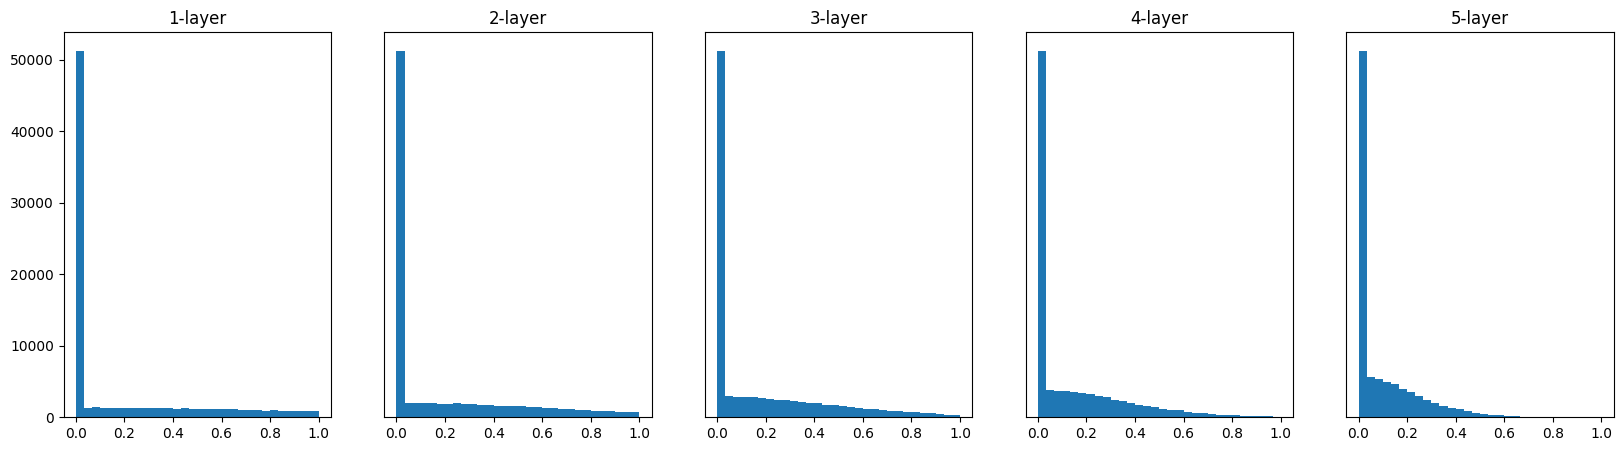

In [ ]:
forward_net(is_sd_const=False, sd=1, ac_func=relu)

In [ ]:
np.std([0, 0, 1, 1])

np.float64(0.5)

In [ ]:
np.std([0, 0.3, 0.6, 1])

np.float64(0.36996621467371854)